# EDA - Energy Efficiency Dataset

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler

def rmse(y_true, y_pred):
    output = np.sqrt(mean_squared_error(y_true, y_pred))
    return output

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

### Import Dataset

In [5]:
# Import energy efficiency dataset
from ucimlrepo import fetch_ucirepo
  
# fetch dataset 
energy_efficiency = fetch_ucirepo(id=242) 
  
# data (as pandas dataframes) 
X = energy_efficiency.data.features 
y = energy_efficiency.data.targets 
  
# metadata 
print(energy_efficiency.metadata) 
  
# variable information 
print(energy_efficiency.variables) 




{'uci_id': 242, 'name': 'Energy Efficiency', 'repository_url': 'https://archive.ics.uci.edu/dataset/242/energy+efficiency', 'data_url': 'https://archive.ics.uci.edu/static/public/242/data.csv', 'abstract': 'This study looked into assessing the heating load and cooling load requirements of buildings (that is, energy efficiency) as a function of building parameters.', 'area': 'Computer Science', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 768, 'num_features': 8, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Y1', 'Y2'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2012, 'last_updated': 'Mon Feb 26 2024', 'dataset_doi': '10.24432/C51307', 'creators': ['Athanasios Tsanas', 'Angeliki Xifara'], 'intro_paper': {'ID': 379, 'type': 'NATIVE', 'title': 'Accurate quantitative estimation of energy performance of residential buildings using statistical machine 

### Read the Dataset Values for get an idea

- All X values

In [6]:
X.T

,0,1,2,3,4,5,6,7,8,9,...,758,759,760,761,762,763,764,765,766,767
X1,0.98,0.98,0.98,0.98,0.9,0.9,0.9,0.9,0.86,0.86,...,0.66,0.66,0.64,0.64,0.64,0.64,0.62,0.62,0.62,0.62
X2,514.50,514.50,514.50,514.50,563.5,563.5,563.5,563.5,588.00,588.00,...,759.50,759.50,784.00,784.00,784.00,784.00,808.50,808.50,808.50,808.50
X3,294.00,294.00,294.00,294.00,318.5,318.5,318.5,318.5,294.00,294.00,...,318.50,318.50,343.00,343.00,343.00,343.00,367.50,367.50,367.50,367.50
X4,110.25,110.25,110.25,110.25,122.5,122.5,122.5,122.5,147.00,147.00,...,220.50,220.50,220.50,220.50,220.50,220.50,220.50,220.50,220.50,220.50
X5,7.00,7.00,7.00,7.00,7.0,7.0,7.0,7.0,7.00,7.00,...,3.50,3.50,3.50,3.50,3.50,3.50,3.50,3.50,3.50,3.50
X6,2.00,3.00,4.00,5.00,2.0,3.0,4.0,5.0,2.00,3.00,...,4.00,5.00,2.00,3.00,4.00,5.00,2.00,3.00,4.00,5.00
X7,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,...,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40
X8,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,...,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00


- Two Target Values

In [7]:
y.T

,0,1,2,3,4,5,6,7,8,9,...,758,759,760,761,762,763,764,765,766,767
Y1,15.55,15.55,15.55,15.55,20.84,21.46,20.71,19.68,19.5,19.95,...,14.92,15.16,17.69,18.19,18.16,17.88,16.54,16.44,16.48,16.64
Y2,21.33,21.33,21.33,21.33,28.28,25.38,25.16,29.60,27.3,21.97,...,17.55,18.06,20.82,20.21,20.71,21.40,16.88,17.11,16.61,16.03


### Remove the qualitative columns
- Because they do not provide a meaningful continuous output like other X variables and they are just like a categorical values. Section only focuses on quantitative variables

In [8]:
df_clean = pd.concat([y['Y1'], X.drop(['X6', 'X8'], axis=1)], axis=1)
df_clean.T

,0,1,2,3,4,5,6,7,8,9,...,758,759,760,761,762,763,764,765,766,767
Y1,15.55,15.55,15.55,15.55,20.84,21.46,20.71,19.68,19.50,19.95,...,14.92,15.16,17.69,18.19,18.16,17.88,16.54,16.44,16.48,16.64
X1,0.98,0.98,0.98,0.98,0.90,0.90,0.90,0.90,0.86,0.86,...,0.66,0.66,0.64,0.64,0.64,0.64,0.62,0.62,0.62,0.62
X2,514.50,514.50,514.50,514.50,563.50,563.50,563.50,563.50,588.00,588.00,...,759.50,759.50,784.00,784.00,784.00,784.00,808.50,808.50,808.50,808.50
X3,294.00,294.00,294.00,294.00,318.50,318.50,318.50,318.50,294.00,294.00,...,318.50,318.50,343.00,343.00,343.00,343.00,367.50,367.50,367.50,367.50
X4,110.25,110.25,110.25,110.25,122.50,122.50,122.50,122.50,147.00,147.00,...,220.50,220.50,220.50,220.50,220.50,220.50,220.50,220.50,220.50,220.50
X5,7.00,7.00,7.00,7.00,7.00,7.00,7.00,7.00,7.00,7.00,...,3.50,3.50,3.50,3.50,3.50,3.50,3.50,3.50,3.50,3.50
X7,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40,0.40


# Y1 as the Target

In [9]:
quan_candidates = df_clean.columns.tolist()
TARGET = 'Y1'
df_clean[quan_candidates].head(10)

,Y1,X1,X2,X3,X4,X5,X7
0,15.55,0.98,514.5,294.0,110.25,7.0,0.0
1,15.55,0.98,514.5,294.0,110.25,7.0,0.0
2,15.55,0.98,514.5,294.0,110.25,7.0,0.0
3,15.55,0.98,514.5,294.0,110.25,7.0,0.0
4,20.84,0.90,563.5,318.5,122.50,7.0,0.0
5,21.46,0.90,563.5,318.5,122.50,7.0,0.0
6,20.71,0.90,563.5,318.5,122.50,7.0,0.0
7,19.68,0.90,563.5,318.5,122.50,7.0,0.0
8,19.50,0.86,588.0,294.0,147.00,7.0,0.0
9,19.95,0.86,588.0,294.0,147.00,7.0,0.0


### shape, Data types, missing values Checking

In [10]:
print("Shape of X:", df_clean[quan_candidates].shape)
print("Shape of y:", y[TARGET].shape)

print("\nData types:")
print(df_clean[quan_candidates].dtypes)
print(y[TARGET].dtypes)

print("\nMissing values:")
print(df_clean[quan_candidates].isnull().sum())
print(y[TARGET].isnull().sum())

Shape of X: (768, 7)
Shape of y: (768,)

Data types:
Y1    float64
X1    float64
X2    float64
X3    float64
X4    float64
X5    float64
X7    float64
dtype: object
float64

Missing values:
Y1    0
X1    0
X2    0
X3    0
X4    0
X5    0
X7    0
dtype: int64
0


# Exploratory Data Analysis

### 1.Univariate Analysis

In [11]:
# Select the columns for the feature matrix
cols = [TARGET] + quan_candidates
descriptions = {
    'Y1': ' Heating Load ',
    'X1': 'Relative Compactness',
    'X2': 'Surface Area',
    'X3': 'Wall Area',
    'X4': 'Roof Area',
    'X5': 'Overall Height',
    'X7': 'Glazing Area'
}

- KDE plot ---> Distribution + skewness

    - KDE plots were selected to examine the distribution, spread, concentration, and skewness of each quantitative variable using a smooth density estimate.

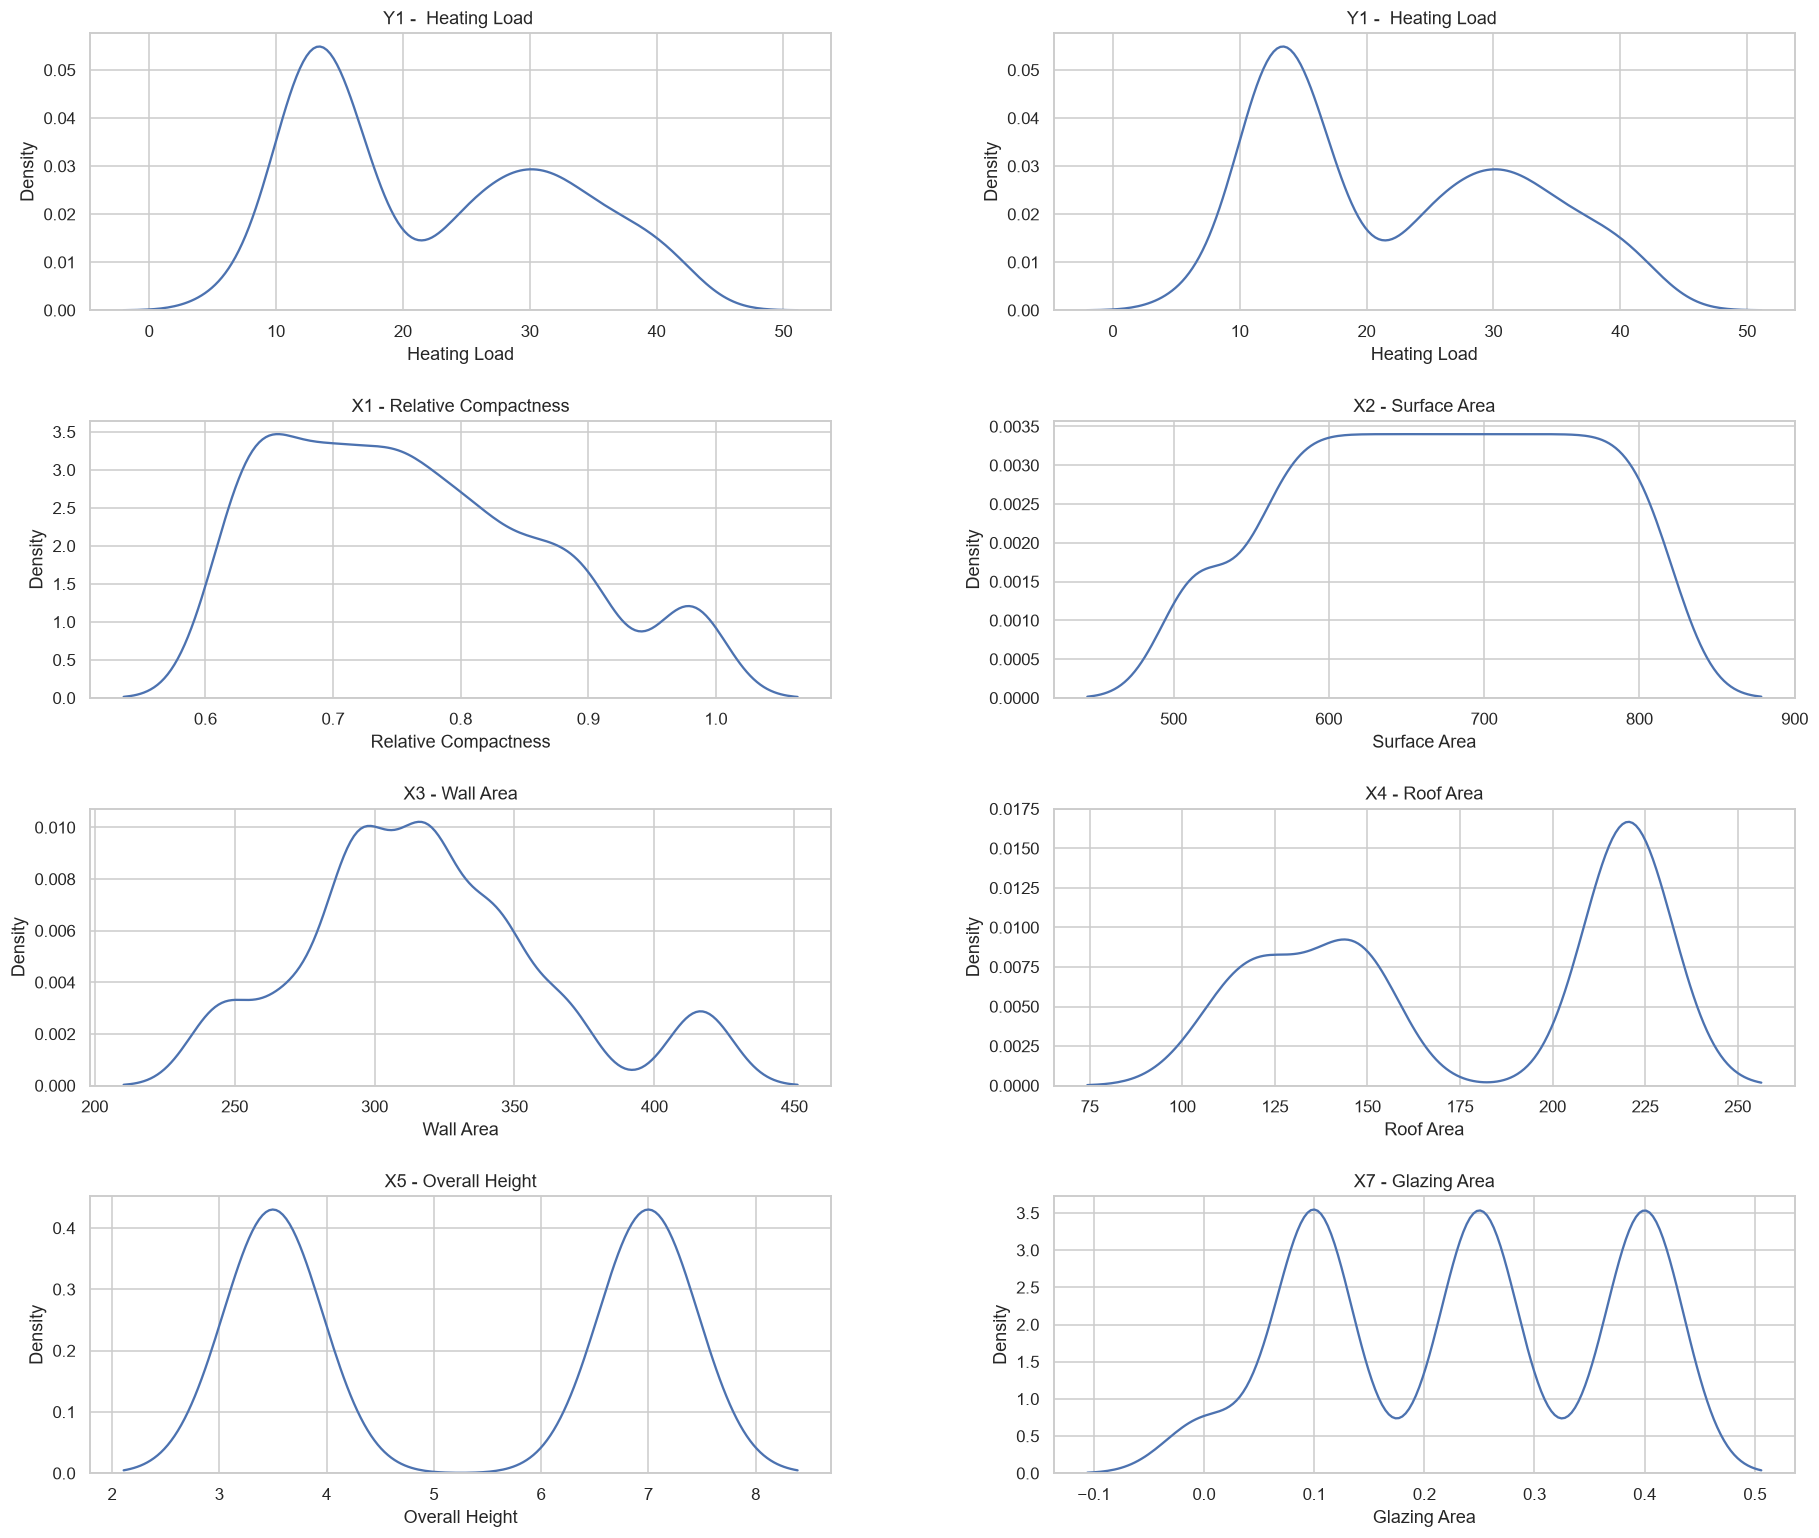

In [12]:
fig, axes = plt.subplots(4,2,figsize=(20,17))
axes = axes.ravel()
for i, c in enumerate(cols):
    sns.kdeplot(data=df_clean, x=c, ax=axes[i])
    axes[i].set_title(f'{c} - {descriptions[c]}')
    axes[i].set_xlabel(descriptions[c])
    axes[i].set_ylabel('Density')
plt.subplots_adjust(hspace=0.4, wspace=0.3) 
plt.show()

- ECDF plots ---> spread

    - ECDF plots are appropriate for univariate analysis because they show the cumulative distribution, allowing the spread, central tendency, skewness, and relative position of observations to be examined without grouping values into bins.

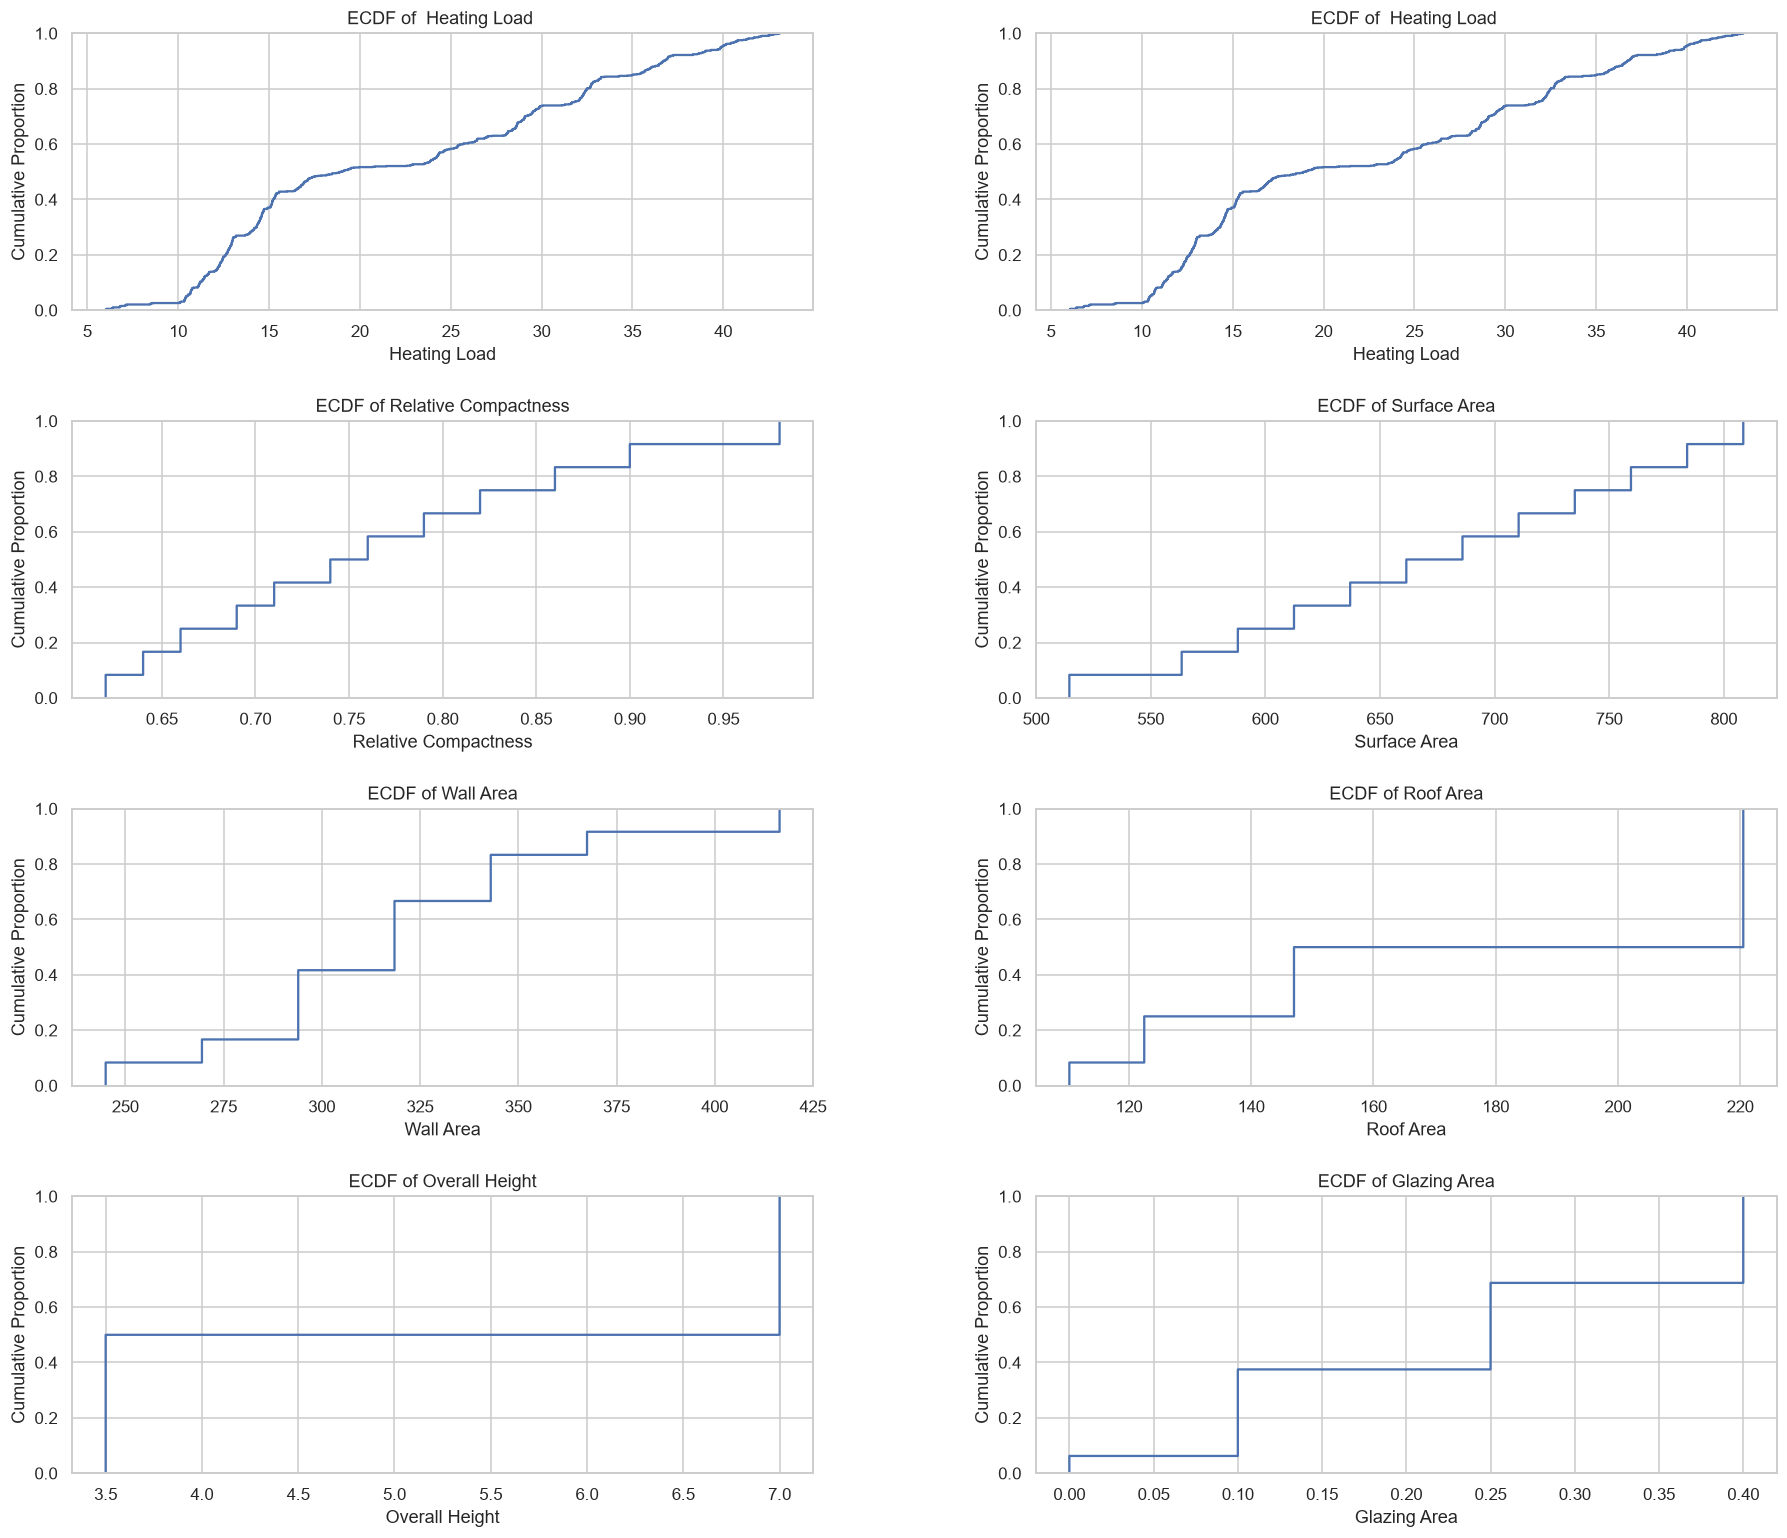

In [13]:
fig, axes = plt.subplots(4,2,figsize=(20,17))
axes = axes.ravel()
for i, c in enumerate(cols):
    sns.ecdfplot(data=df_clean, x=c, ax=axes[i])
    axes[i].set_title(f'ECDF of {descriptions[c]}')
    axes[i].set_xlabel(descriptions[c])
    axes[i].set_ylabel('Cumulative Proportion')
plt.subplots_adjust(hspace=0.4, wspace=0.3) 
plt.show()

- Violine plots - Skewness

    - Violin plots are appropriate for univariate analysis because they show the distribution and density of each variable together with its spread, central tendency, and possible extreme observations

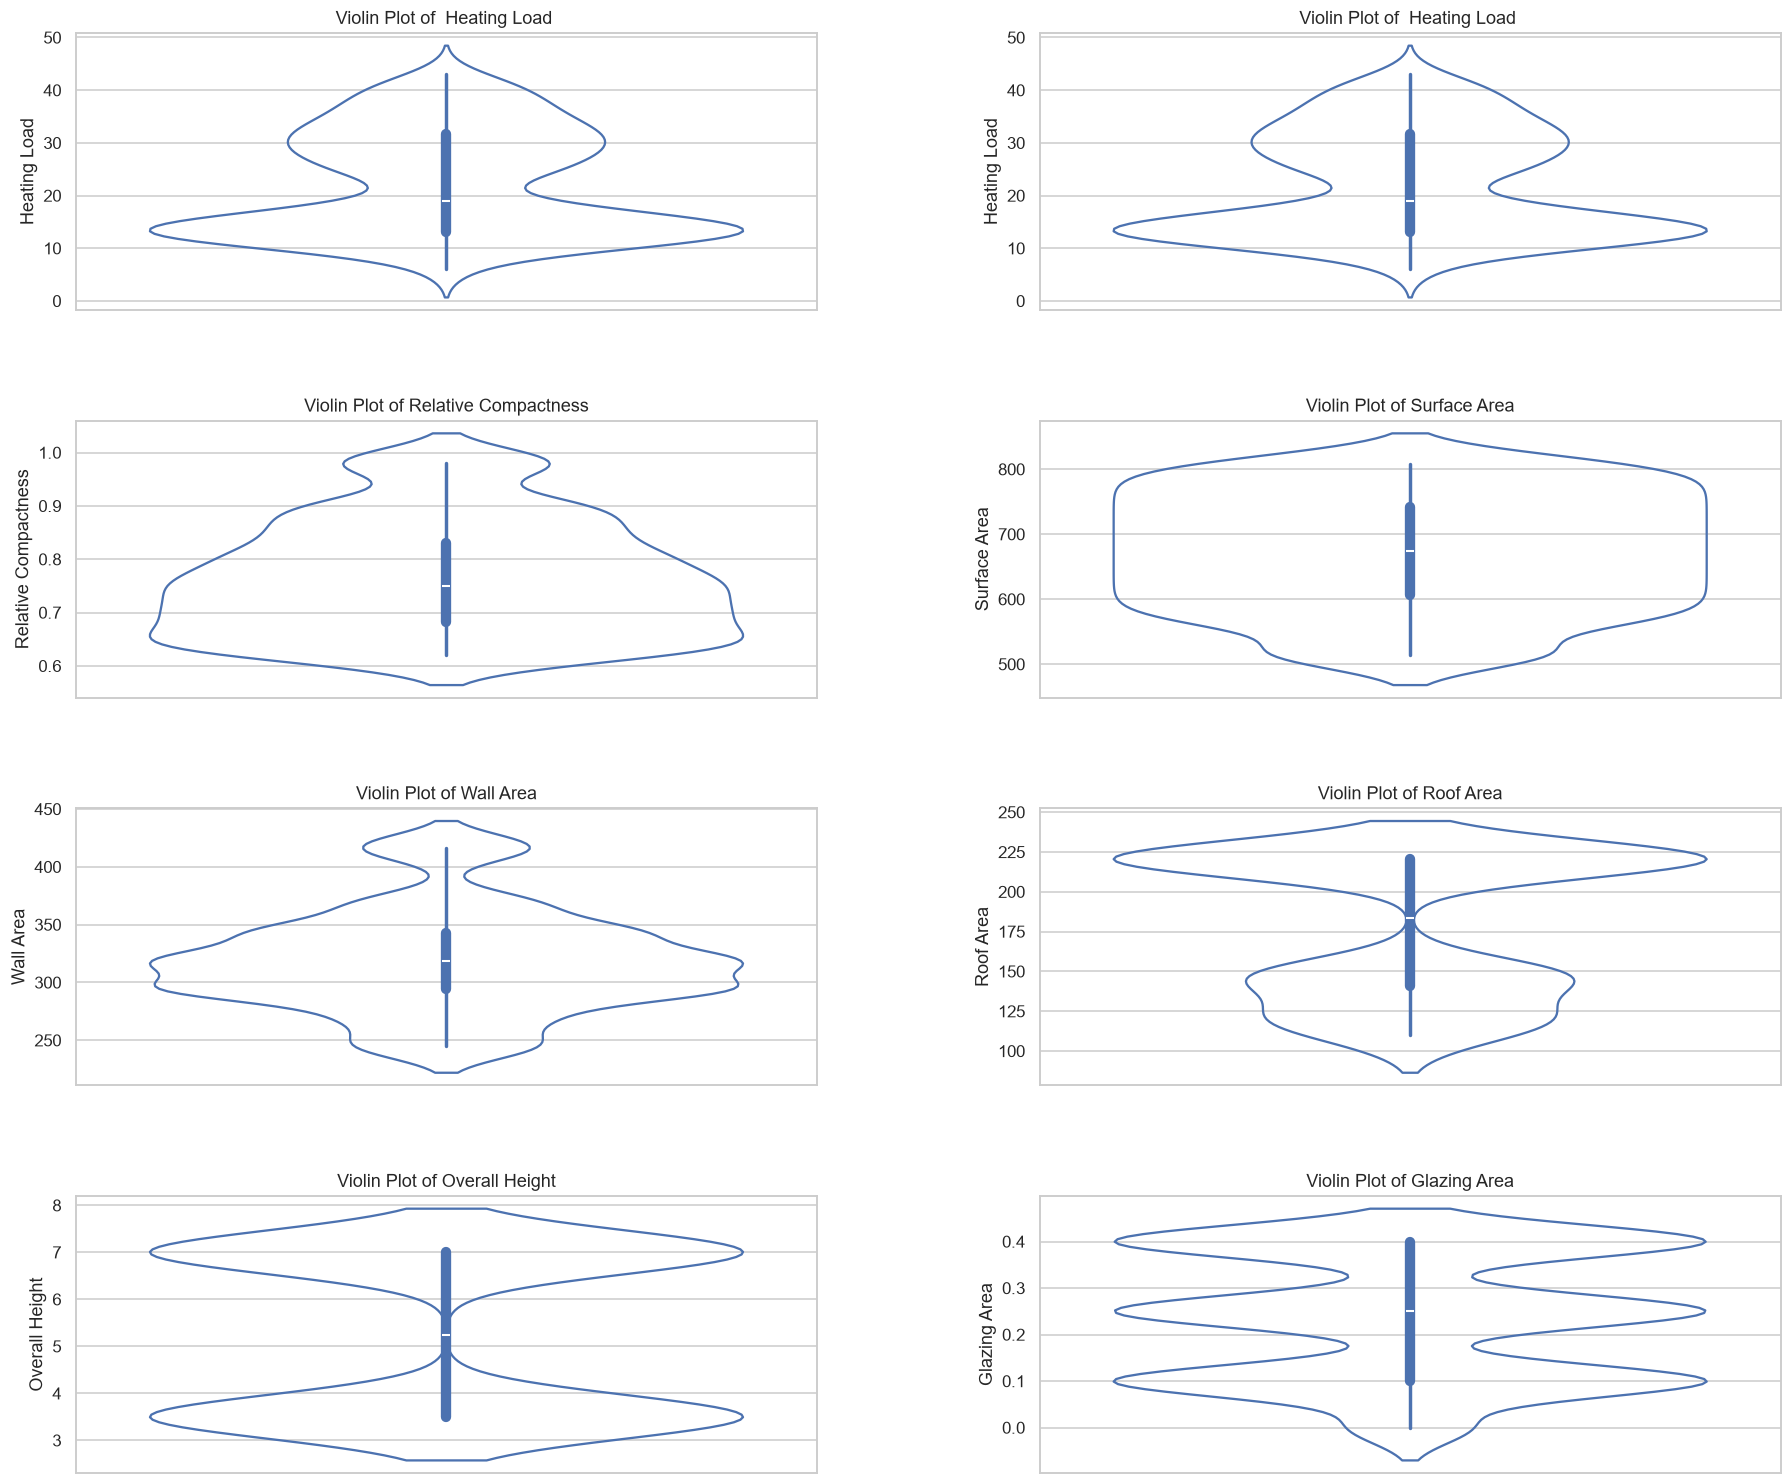

In [14]:
fig, axes = plt.subplots(4, 2, figsize=(20, 17))
axes = axes.ravel()
for i, c in enumerate(cols):
    sns.violinplot(
        data=df_clean,
        y=c,
        ax=axes[i],
        fill=0
    )
    axes[i].set_title(f'Violin Plot of {descriptions[c]}')
    axes[i].set_ylabel(descriptions[c])
    axes[i].set_xlabel('')
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()

### 2. Bivariate Analysis

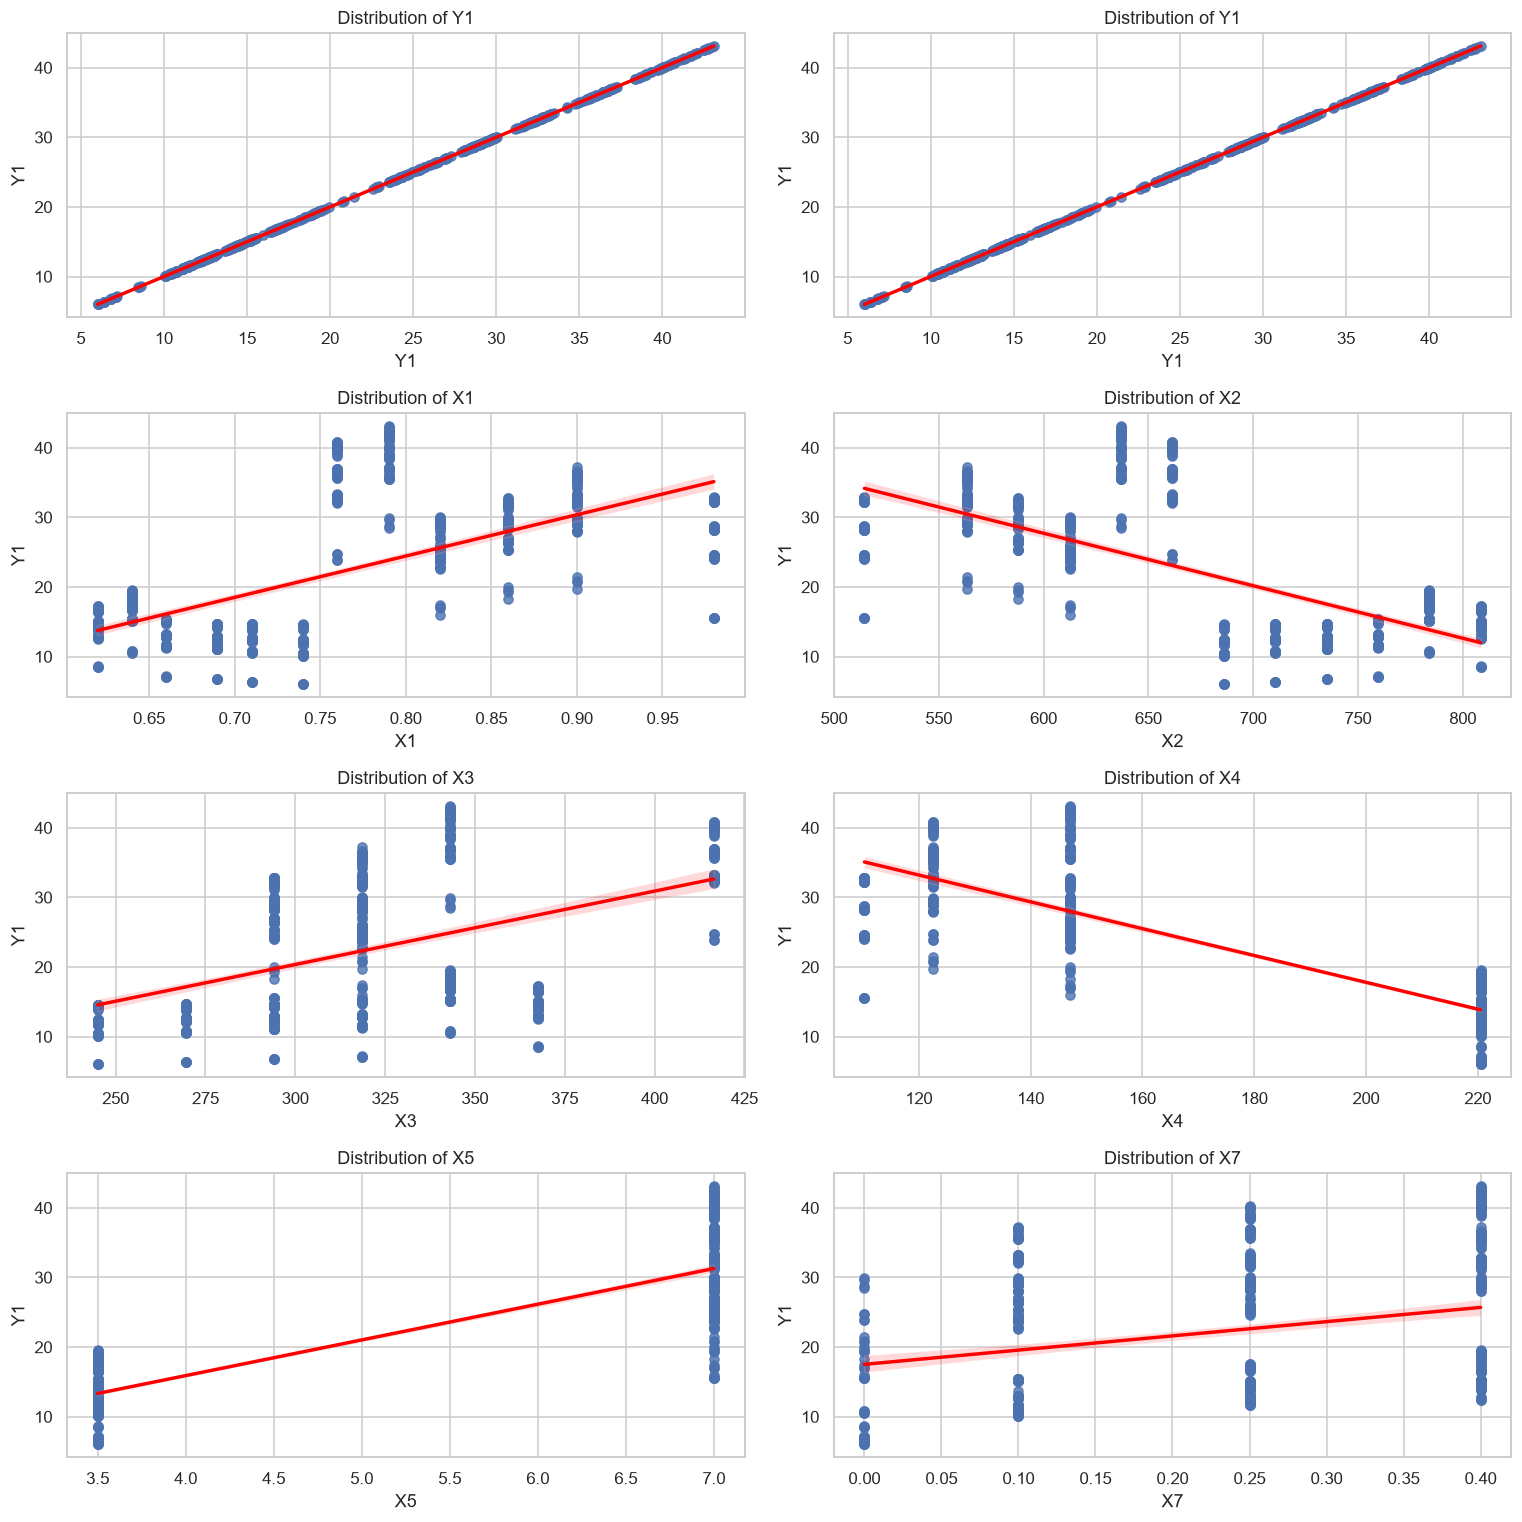

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(14,14))
axes = axes.ravel()
for i, c in enumerate(cols[:8]):
    sns.regplot(data=df_clean, x=c, y=TARGET, ax=axes[i], line_kws={'color':'red'})
    axes[i].set_title(f"Distribution of {c}")
plt.tight_layout()
plt.show()

### 3. Correlational Analysis

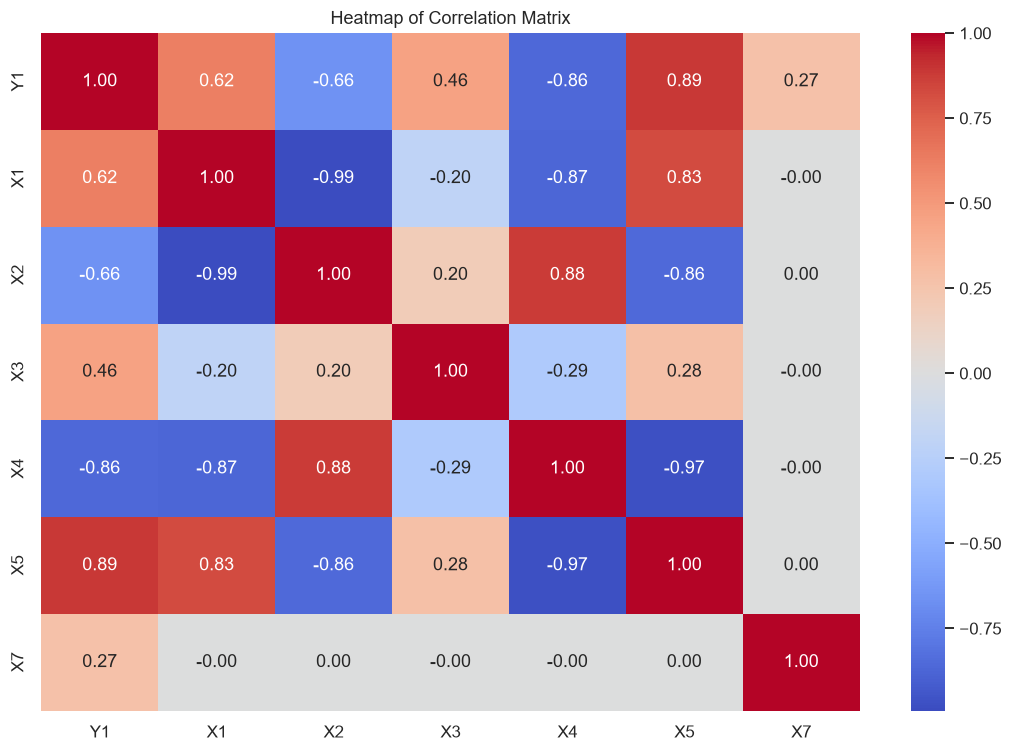

In [16]:
plt.figure(figsize=(12, 8))
sns.heatmap(df_clean.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Heatmap of Correlation Matrix")
plt.show()

In [17]:
df_clean.corr()

,Y1,X1,X2,X3,X4,X5,X7
Y1,1.000000,6.222722e-01,-6.581202e-01,4.556712e-01,-8.618283e-01,8.894307e-01,2.698410e-01
X1,0.622272,1.000000e+00,-9.919015e-01,-2.037817e-01,-8.688234e-01,8.277473e-01,-2.960552e-15
X2,-0.658120,-9.919015e-01,1.000000e+00,1.955016e-01,8.807195e-01,-8.581477e-01,3.636925e-15
X3,0.455671,-2.037817e-01,1.955016e-01,1.000000e+00,-2.923165e-01,2.809757e-01,-8.567455e-17
X4,-0.861828,-8.688234e-01,8.807195e-01,-2.923165e-01,1.000000e+00,-9.725122e-01,-1.759011e-15
X5,0.889431,8.277473e-01,-8.581477e-01,2.809757e-01,-9.725122e-01,1.000000e+00,1.489134e-17
X7,0.269841,-2.960552e-15,3.636925e-15,-8.567455e-17,-1.759011e-15,1.489134e-17,1.000000e+00


# Findings: Exploratory Data Analysis (Y1 — Heating Load)

- 1. Predictor Relationships & Direction

    - Overall Height (X5) ---> strongest positive predictor (r = +0.89)

        - Taller buildings generally have higher Heating Loads, while shorter buildings have lower Heating Loads.

    - Roof Area (X4) ---> strongest negative predictor (r = -0.86)

        - Larger roof areas generally have lower Heating Loads, while smaller roof areas have higher Heating Loads.

    - Surface Area (X2) & Relative Compactness (X1)

        - Surface Area has a negative relationship with Heating Load (r = -0.66), while Relative Compactness has a positive relationship (r = +0.62).

    - Wall Area (X3) ---> moderate positive predictor (r = +0.46)

        - Larger wall areas generally result in higher Heating Loads.

    - Glazing Area (X7) ---> weak positive predictor (r = +0.27)

        - Increasing glazing area generally increases Heating Load.

- 2. Shape of Relationships

    - Overall Height (X5) ---> step-wise relationship

        - The relationship is step-wise because there are only two building heights: 3.5 m and 7.0 m.

    - Glazing Area (X7) ---> four groups

        - The data forms four groups because glazing area has only four values: 0.0, 0.10, 0.25, and 0.40.

    - Roof Area (X4) ---> clear difference between large and small roof areas

        - Buildings with a roof area of 220.5 m² have lower Heating Loads, while smaller roof areas can have much higher Heating Loads.

    - Relative Compactness (X1) & Surface Area (X2) ---> non-linear relationship

        - These variables have a non-linear relationship because they are mathematically related.

- 3. Distribution, Skewness & Outliers

    - Heating Load (Y1) ---> two main groups

        - Heating Load has two main groups, around 13–14 kWh/m² and 30–32 kWh/m².

    - Wall Area (X3) ---> concentrated around 300–320 m²

        - Most Wall Area values are around 300–320 m², with some higher values around 416.5 m².

    - Outliers ---> no major unusual values

        - The data does not show any major unusual or corrupted values. The dataset contains 768 controlled simulation results.

- 4. Multicollinearity Among Predictors

    - Relative Compactness (X1) & Surface Area (X2) ---> almost perfect negative relationship (r = -0.99)

        - These variables are strongly related because they are mathematically connected.

    - Roof Area (X4) & Overall Height (X5) ---> very strong negative relationship (r = -0.97)

        - Taller buildings generally have smaller roof areas.

    - Other Geometric Variables ---> strong relationships

        - Roof Area and Height also have strong relationships with Surface Area and Relative Compactness.

    - Glazing Area (X7) ---> almost no relationship with other geometric variables (r = 0.00)

        - This means Glazing Area was treated as an independent factor in the simulation.

### Model Training

In [19]:
Y = df_clean[TARGET].values
X = df_clean[quan_candidates].values

### Split Data

In [20]:

train_size = 0.75
test_size = 0.25

x_train, x_test, y_train, y_test = train_test_split(X, Y, train_size=train_size, test_size=test_size, random_state=42)

In [21]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((576, 7), (192, 7), (576,), (192,))

### Train the model

In [22]:
model = LinearRegression()
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 1.,-0.,-0.,..., 0.,-0., 0.]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.974e-14
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,6
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](7,)","[2338.33,1127.25, 109.61,..., 2.35, 0.24, 0. ]"


## β values

In [24]:
model.coef_.tolist()

[1.000000000000001,
 -3.729942957087038e-14,
 -5.92624116024458e-16,
 6.318419498555052e-16,
 1.3352506756179191e-15,
 -1.004487388432845e-15,
 1.8424400206395322e-16]

In [26]:
model.intercept_.tolist()

-4.973799150320701e-14

In [27]:
coefficients = pd.DataFrame(model.coef_, quan_candidates, columns=['Coefficient'])
coefficients

,Coefficient
Y1,1.000000e+00
X1,-3.729943e-14
X2,-5.926241e-16
X3,6.318419e-16
X4,1.335251e-15
X5,-1.004487e-15
X7,1.842440e-16


In [28]:
Y_pred = model.predict(x_test)
Y_pred

array([16.47, 13.17, 32.82, 41.32, 16.69, 23.8 , 24.31, 28.67, 19.52,
       28.07, 18.46, 33.08, 29.79, 10.37, 17.69, 36.95, 36.64, 12.3 ,
       14.7 , 32.38, 28.67, 41.4 , 11.7 , 36.86, 15.37, 35.89, 36.57,
       28.91, 17.5 , 13.99, 10.42, 12.3 , 16.93, 26.84, 35.94, 28.18,
       32.72, 36.9 , 36.06, 10.7 , 28.15, 12.32,  6.37, 31.84,  6.79,
        6.4 ,  7.1 , 10.8 , 28.66, 32.46, 34.95, 12.93, 13.  , 40.12,
       12.27, 15.32, 12.45, 24.6 , 40.68, 35.99, 14.37, 16.54, 13.02,
       22.89, 28.61, 37.1 , 35.45, 11.68, 13.  , 12.03, 29.14, 32.84,
       12.47, 24.23, 31.64, 12.16, 29.06, 24.7 , 32.26, 19.34, 24.38,
       40.  , 10.68, 13.91, 11.6 , 12.43, 26.46, 36.13, 37.12, 17.37,
       15.18, 25.38, 11.13, 12.95, 36.59, 12.86, 25.36, 28.31, 10.66,
       10.71, 40.78, 28.37, 10.36, 29.83, 29.43, 16.76, 22.58, 16.44,
       14.08, 12.41, 33.12, 32.31, 24.63, 14.72, 11.69, 14.66, 11.2 ,
       10.39, 12.12, 19.68, 29.06, 11.16, 23.93, 14.6 , 29.68, 17.88,
       14.53, 35.48,

In [29]:
# Y_test, Y_pred
eval = rmse(y_test, Y_pred)
eval

np.float64(2.1440147666555573e-14)

In [30]:
# Mean Squared Error
mse = mean_squared_error(y_test, Y_pred)
mse

4.596799319637084e-28

In [31]:
# Mean Absolute Error
mae = mean_absolute_error(y_test, Y_pred)
mae

1.9609314172441827e-14

# Model performance
- The model explains **100% of the variance in Heating Load (R² = 1.00)**. The typical prediction error is essentially **0 kWh/m²**, with an RMSE of approximately **2.14 × 10⁻¹⁴ kWh/m²**, meaning the predictions are almost exactly equal to the actual values.


# Interpreting model parameters

- 1. Predictor Coefficients

    - X1. Relative Compactness ---> coefficient is very close to zero

        - When X1 goes up by one unit, there is almost no change in the predicted Heating Load.

    - X2. Surface Area ---> coefficient is very close to zero

        - A one-unit increase in X2 leads to almost no change in the predicted Heating Load.

    - X3. Wall Area ---> coefficient is almost zero

        - For every one-unit increase in X3, there is almost no effect on the predicted Heating Load.

    - X4. Roof Area ---> coefficient is almost zero

        - Increasing X4 by one unit has almost no impact on the predicted Heating Load.

    - X5. Overall Height ---> coefficient is very close to zero

        - A one-unit increase in X5 results in almost no change in the predicted Heating Load.

    - X7. Glazing Area ---> coefficient is almost zero

        - A one-unit increase in X7 causes almost no difference in the predicted Heating Load.

- 2. Intercept

    - Intercept ---> approximately 1.00

        - When all predictor values are zero, the predicted Heating Load is about 1 kWh/m². However, a building with all these values equal to zero is not realistic, so the intercept has little practical meaning.

- 3. Overall Interpretation

    - Model results ---> almost zero coefficients for all predictors

        - The coefficients are almost zero because Y1 was included as an input when predicting Y1. The model is therefore almost directly using the actual Heating Load to predict itself.

    - Model performance ---> R² = 1.00

        - This explains why the model shows 100% of the variance and has an almost zero prediction error.